# QFF 2026 Phase 2 — PS-S1 reproducible results

This notebook uses the official locked kit, frozen Processor D, generated result tables, and figures. The default `RECOMPUTE = False` path validates saved results and renders the figures; it does not start the 84-run optimizer sweep or Bell experiment. The separate optional N=6 VQE attempt is incomplete and clearly marked as supplemental.


In [1]:
from pathlib import Path
import csv, json, subprocess, sys, importlib.metadata as md
ROOT = Path.cwd()
assert (ROOT / 'qff_sim.py').exists() and (ROOT / 'processors/processor_D.json').exists(), 'Run this notebook from the repository root.'
PYTHON = Path(sys.executable)
RECOMPUTE = False  # flip to True for the official required N=4 compute path
if RECOMPUTE:
    subprocess.run([str(PYTHON), 'src/run_s1.py'], cwd=ROOT, check=True)
    subprocess.run([str(PYTHON), 'src/finish_stage_b.py'], cwd=ROOT, check=True)
print('Repository: current project root')
for package in ('qiskit','qiskit-aer','numpy','scipy','matplotlib','notebook','nbconvert','ipykernel'):
    try: print(f'{package}=={md.version(package)}')
    except md.PackageNotFoundError: print(f'{package}: NOT INSTALLED')

Repository: current project root
qiskit==1.4.6
qiskit-aer==0.18.0
numpy==2.4.6
scipy==1.17.1
matplotlib==3.11.2
notebook==7.6.3
nbconvert==7.17.2
ipykernel==7.4.0


In [2]:
def read_csv(path):
    with (ROOT/path).open(newline='', encoding='utf-8') as f: return list(csv.DictReader(f))

# Locked settings and exact-reference metadata gate.
sys.path.insert(0, str(ROOT))
import qff_sim as sim
g_values = [0.25,0.50,0.75,1.00,1.25,1.50,2.00]
assert len(read_csv('results/tables/s1_exact_reference.csv')) == 7
for g in g_values:
    obj=json.loads((ROOT/'data/s1'/f'tfim_open_N4_g{g:.2f}.json').read_text())
    H=sim.SparsePauliOp.from_list([(lab,float(c)) for lab,c in obj['operator']])
    vals,_=sim.exact_spectrum(H,2)
    assert abs(float(vals[0])-float(obj['meta']['E0_exact'])) < 1e-9
    assert abs(float(vals[1])-float(obj['meta']['E1_exact'])) < 1e-9
print('Exact references: all 7 supplied N=4 instances match E0/E1 metadata at 1e-9.')
# Frozen Processor D validation at both required logical-qubit checks.
for nq in (4,6):
    result=subprocess.run([str(PYTHON),'tools/check_processor_d.py','processors/processor_D.json',str(nq)],cwd=ROOT,text=True,capture_output=True,check=True)
    print(result.stdout.strip())

Exact references: all 7 supplied N=4 instances match E0/E1 metadata at 1e-9.


OK - Processor D satisfies all design rules.


OK - Processor D satisfies all design rules.


In [3]:
# Coverage and core results. Aggregation selects the minimum final energy from seeds 0,1,2; all fields are taken from that same winning run.
agg=read_csv('results/tables/s1_results.csv')
raw=read_csv('results/raw/s1_seed_runs.csv')
layer=read_csv('results/tables/layer_study.csv')
noisy=read_csv('results/tables/s1_noisy.csv')
resources=read_csv('results/tables/resources.csv')
assert len(agg)==28 and len(raw)==84 and len(layer)==28
assert {float(r['g']) for r in agg}==set(g_values)
assert {float(r['g']) for r in noisy}=={0.5,1.0,2.0}
assert {r['processor'] for r in resources}=={'A','B','D'}
resource_labels={r['circuit_label'] for r in resources}
assert {'s1_hva_g1.00_L3_best_seed2_cx','s1_hva_g1.00_L3_best_seed2_rzz','bell_auto_layout_ZZ'} <= resource_labels
assert len(resources)==9
p2_comparison=read_csv('results/additional/p2_processor_comparison.csv')
assert len(p2_comparison)==36
n6_minimal=read_csv('results/additional/s1_n6_minimal_layers.csv')
assert len(n6_minimal)==7
finite_scaling=read_csv('results/additional/finite_size_scaling.csv')
finite_crossings=read_csv('results/additional/finite_size_crossings.csv')
mitigation=read_csv('results/additional/mitigation_d_results.csv')
mitigation_costs=read_csv('results/additional/mitigation_d_costs.csv')
assert len(finite_scaling)==180 and len(finite_crossings)==4
assert len(mitigation)==15 and len(mitigation_costs)==1
assert {float(r['g']) for r in mitigation}=={0.5,1.0,2.0}
assert {r['observable'] for r in mitigation}=={'energy','mx','czz_nn','mz2','mz'}
assert all(r['scope']=='additional, not part of the official required results' for r in mitigation)
assert sum(str(r['reference_checked']).lower()=='true' for r in finite_scaling)==14
failed=[r for r in raw if str(r['success']).lower() not in ('true','1')]
print(f'VQE aggregate rows={len(agg)}; seed-specific rows={len(raw)}; layer rows={len(layer)}; nonconverged optimizer stops retained={len(failed)}')
print('The two iteration-limit starts remain in raw/s1_seed_runs.csv and were not discarded.')
print('A/B/D resources include both CX and RZZ HVA encodings plus Bell auto-layout rows; supplemental p2 comparison rows:',len(p2_comparison))
print('Additional N=6 minimal layers (threshold applies to numeric |energy error|; optimizer flags retained):')
for r in n6_minimal: print({k:r[k] for k in ('g','minimal_L_abs_err_lt_1e-3','selected_energy_error','selected_optimizer_success','failed_starts_at_selected_L')})
print('Additional sparse finite-size rows:',len(finite_scaling),'; N=4/6 official-ref grid points:',sum(str(r['reference_checked']).lower()=='true' for r in finite_scaling))
print('N-gap crossings:',[(r['N_small'],r['N_large'],r['g_crossing_linear_interpolation']) for r in finite_crossings])
print('g | L4 energy error | L4 fidelity | mx (exact) | Czz_nn (exact) | mz2 (exact)')
for r in sorted((x for x in agg if int(x['layers'])==4),key=lambda x:float(x['g'])):
    print(f"{float(r['g']):.2f} | {float(r['energy_err']):.3g} | {float(r['fidelity']):.9f} | {float(r['mx']):.6f} ({float(r['mx_exact']):.6f}) | {float(r['czz_nn']):.6f} ({float(r['czz_nn_exact']):.6f}) | {float(r['mz2']):.6f} ({float(r['mz2_exact']):.6f})")
print('Noisy Processor D rows:')
for r in noisy: print({k:r[k] for k in ('g','layers','energy_noisy','fidelity_noisy_dm','mx_noisy','czz_nn_noisy','mz2_noisy')})
print('Additional D mitigation rows:',len(mitigation),'; cost rows:',len(mitigation_costs),'; extra circuits/shots vs alpha=1:',mitigation_costs[0]['extra_circuits_vs_raw_alpha_1'],mitigation_costs[0]['extra_shots_vs_raw_alpha_1'])


VQE aggregate rows=28; seed-specific rows=84; layer rows=28; nonconverged optimizer stops retained=2
The two iteration-limit starts remain in raw/s1_seed_runs.csv and were not discarded.
A/B/D resources include both CX and RZZ HVA encodings plus Bell auto-layout rows; supplemental p2 comparison rows: 36
Additional N=6 minimal layers (threshold applies to numeric |energy error|; optimizer flags retained):
{'g': '0.25', 'minimal_L_abs_err_lt_1e-3': '8', 'selected_energy_error': '0.0006930754981429033', 'selected_optimizer_success': 'True', 'failed_starts_at_selected_L': '1'}
{'g': '0.5', 'minimal_L_abs_err_lt_1e-3': 'NOT_REACHED_L<=8', 'selected_energy_error': '0.0023816061291528356', 'selected_optimizer_success': 'False', 'failed_starts_at_selected_L': '2'}
{'g': '0.75', 'minimal_L_abs_err_lt_1e-3': 'NOT_REACHED_L<=8', 'selected_energy_error': '0.009126312783711121', 'selected_optimizer_success': 'False', 'failed_starts_at_selected_L': '3'}
{'g': '1.0', 'minimal_L_abs_err_lt_1e-3': 'NOT

phase_observables_vs_g.png


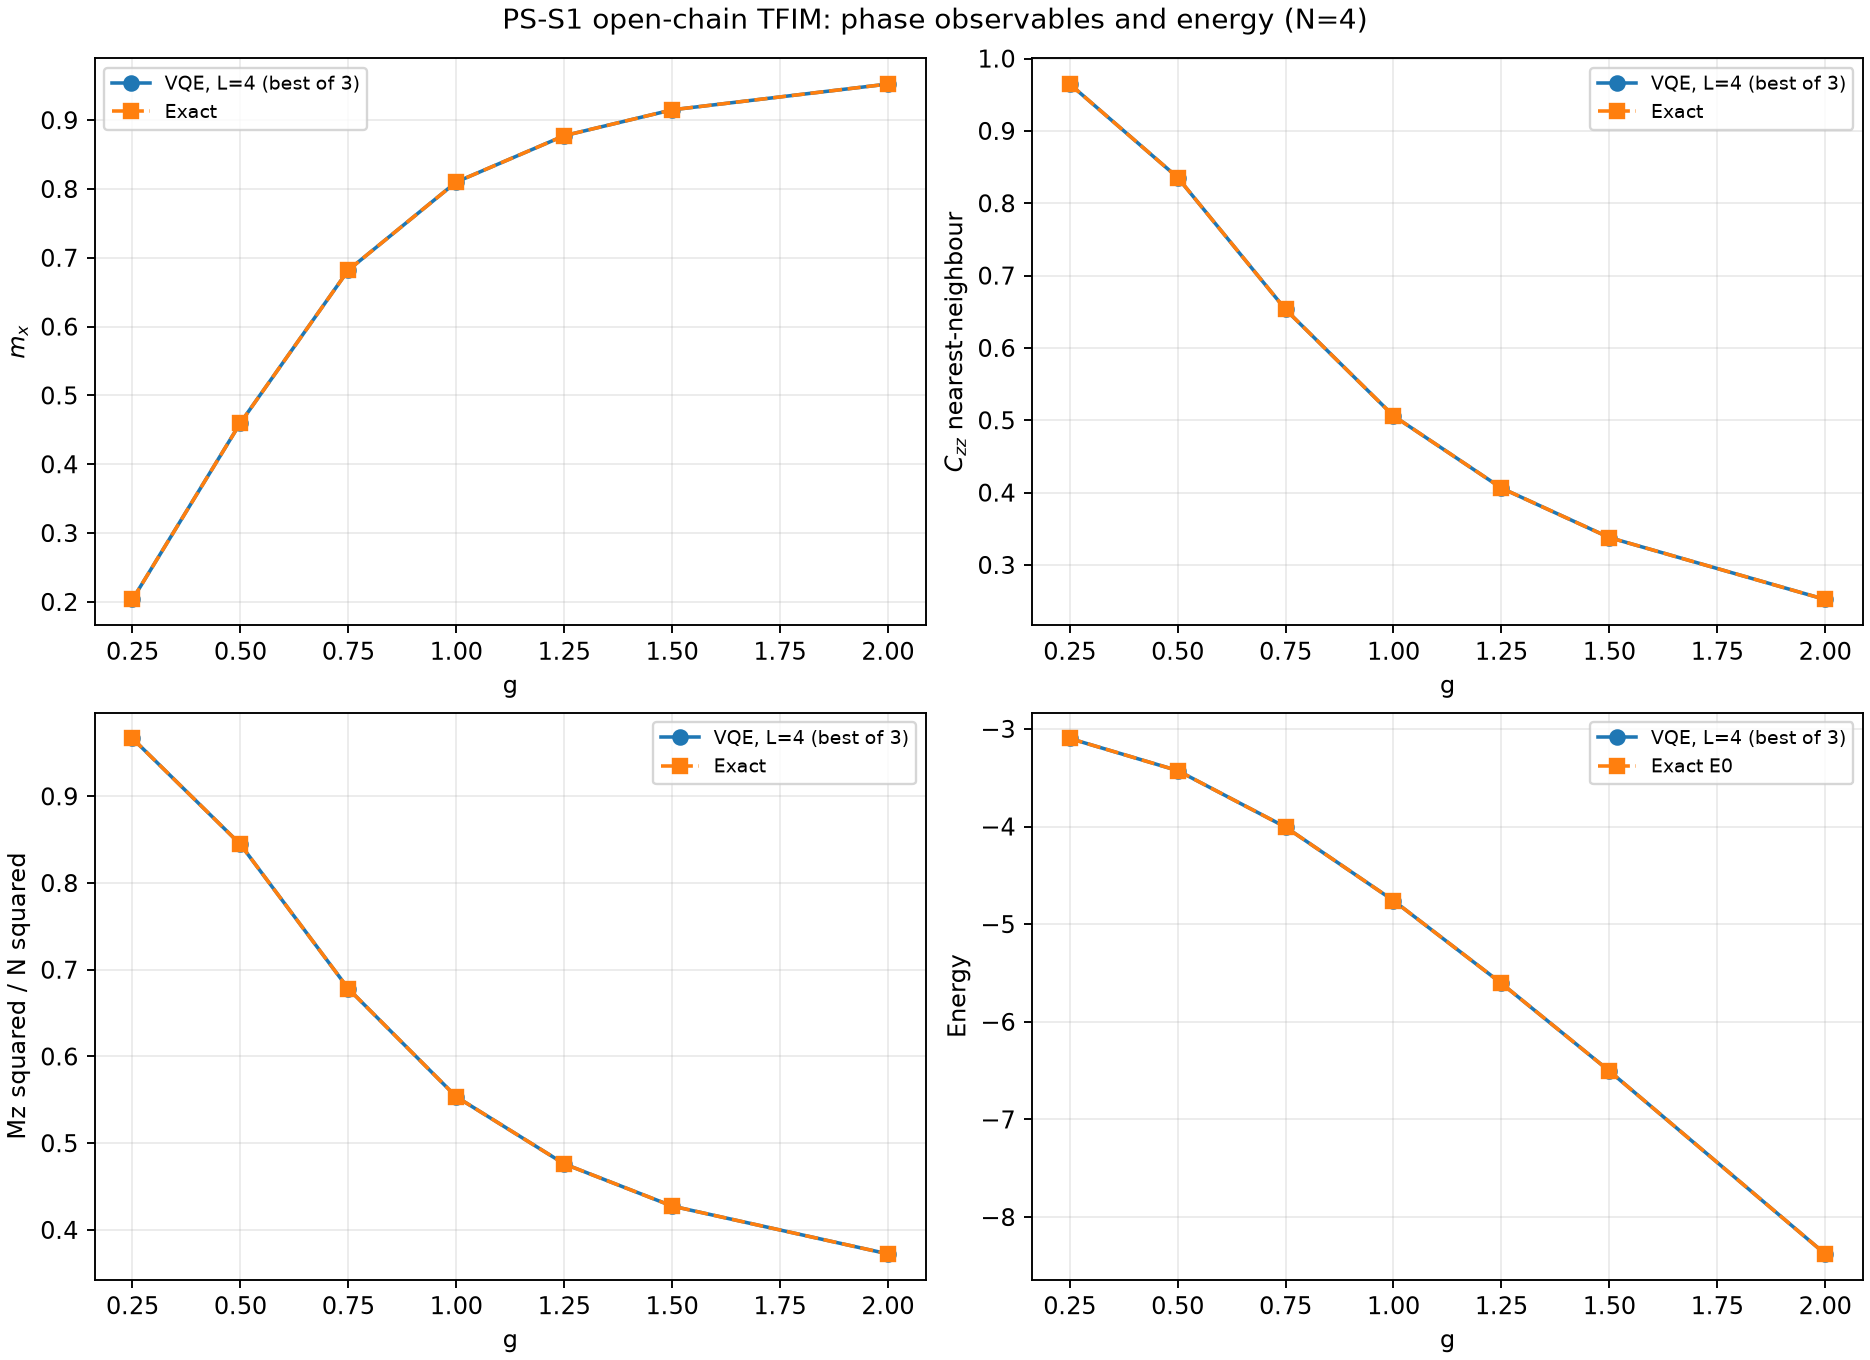

layer_study_convergence.png


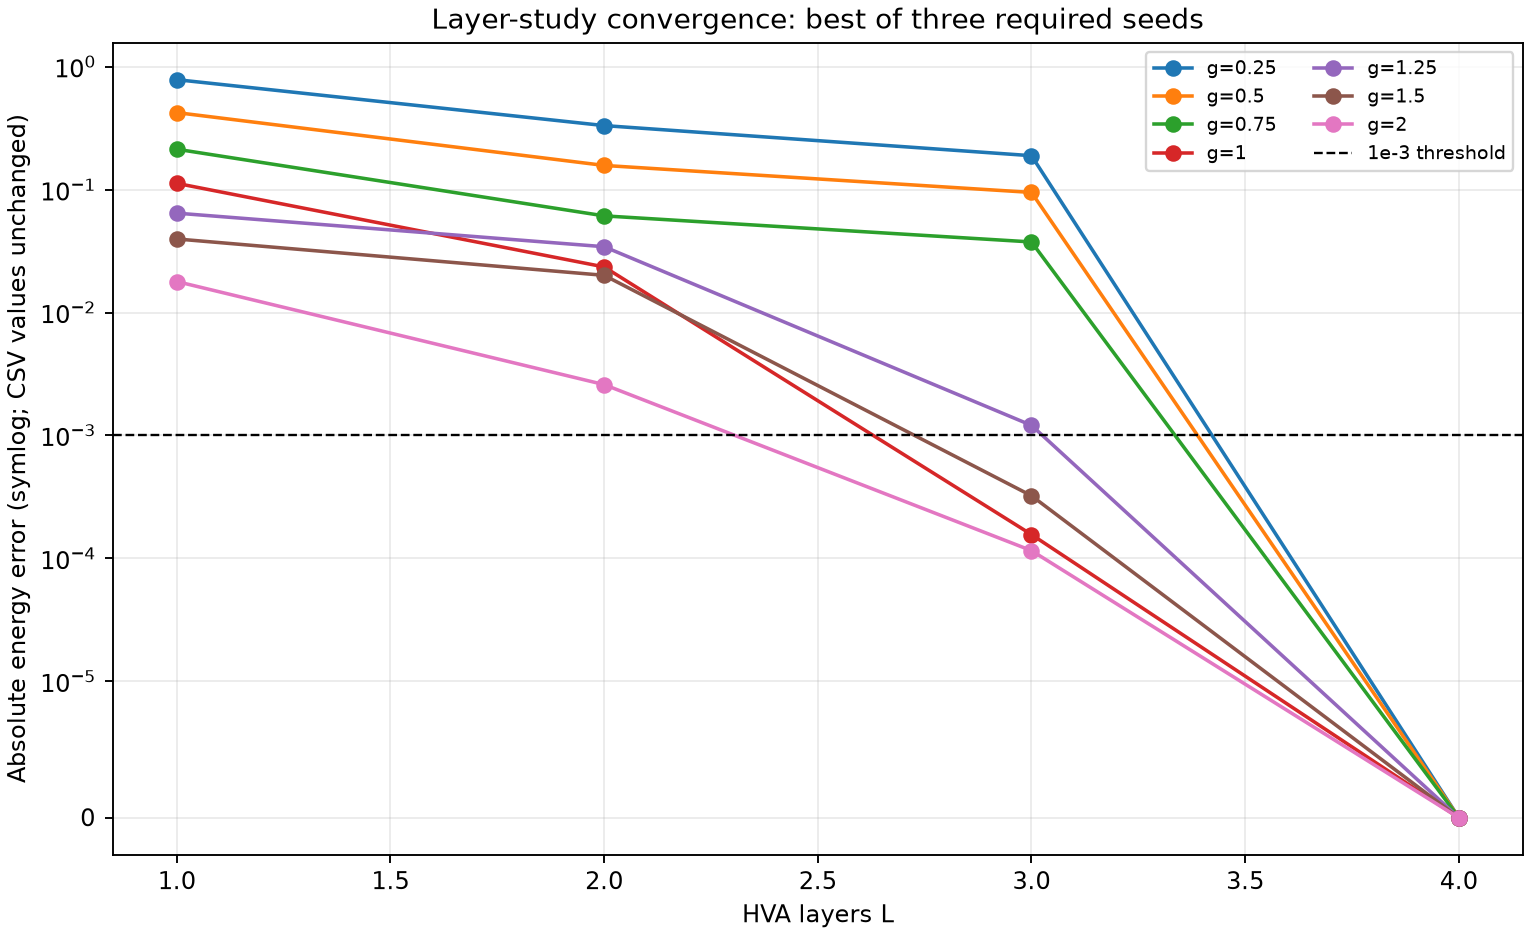

bell_comparison.png


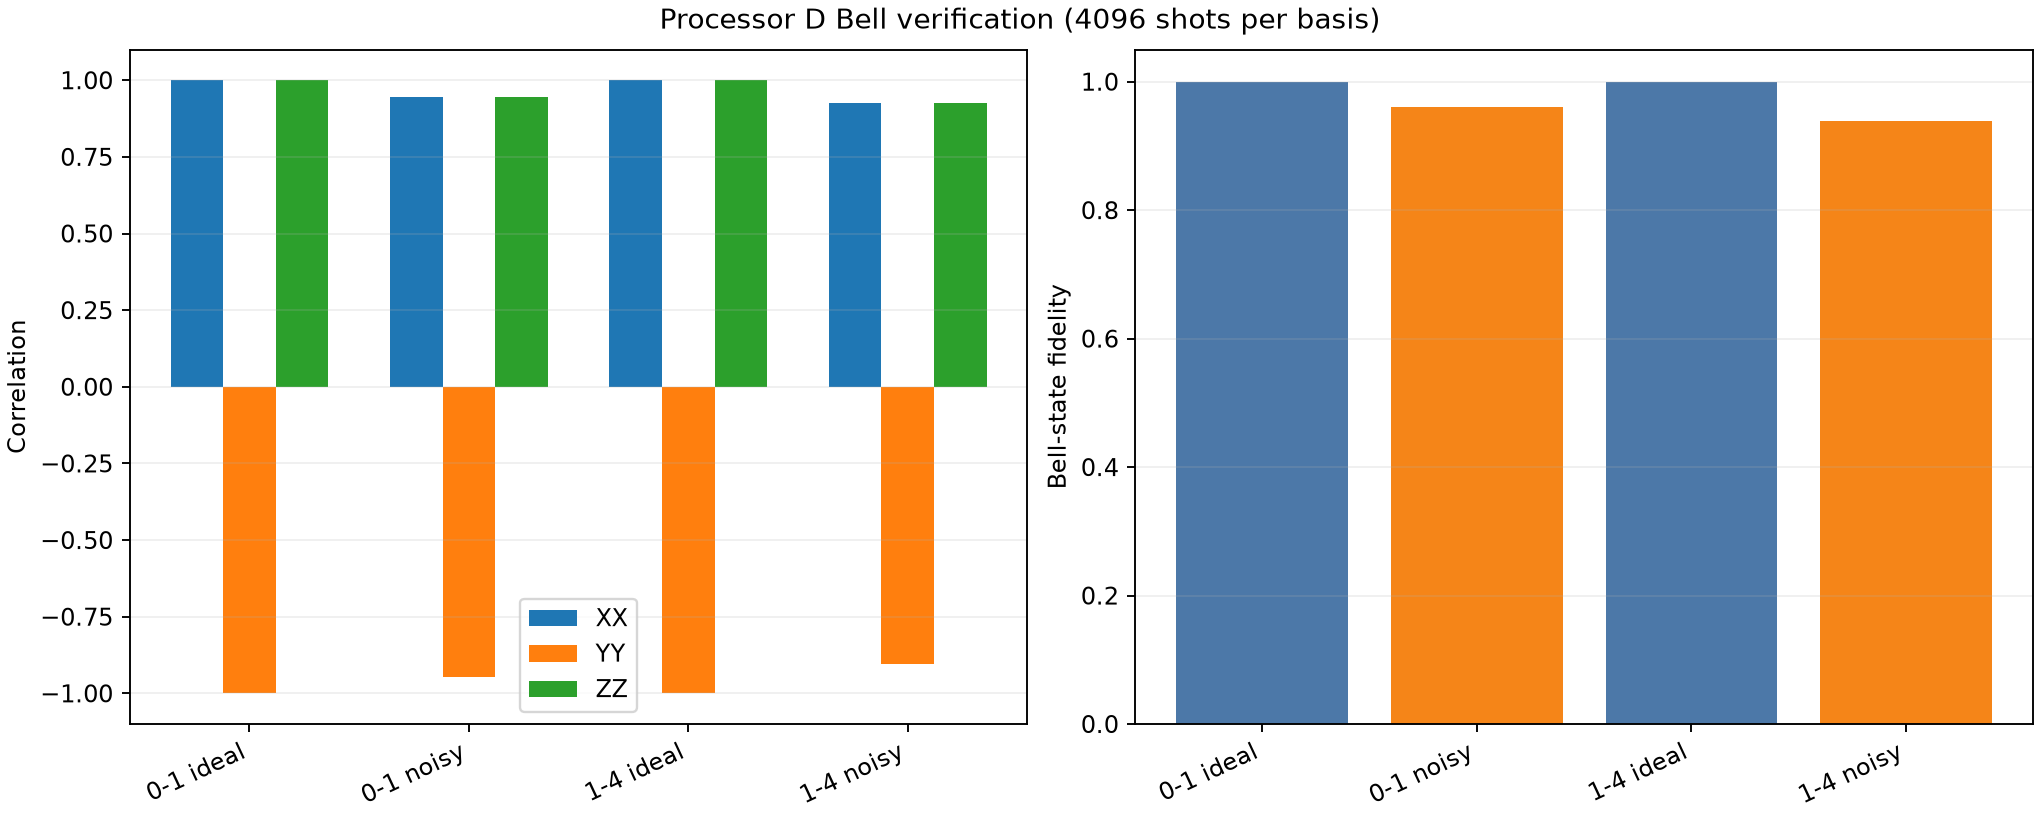

processor_D_topology.png


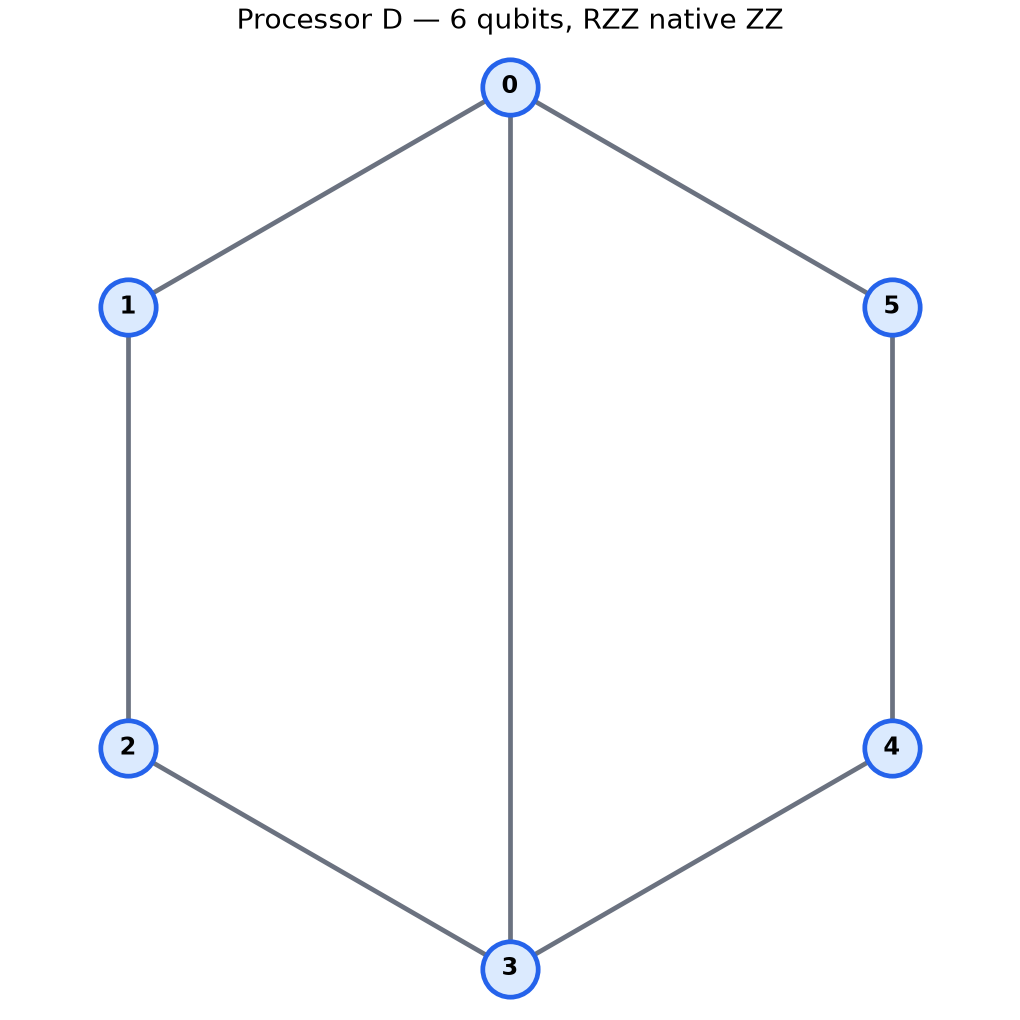

noisy_vs_ideal_energy.png


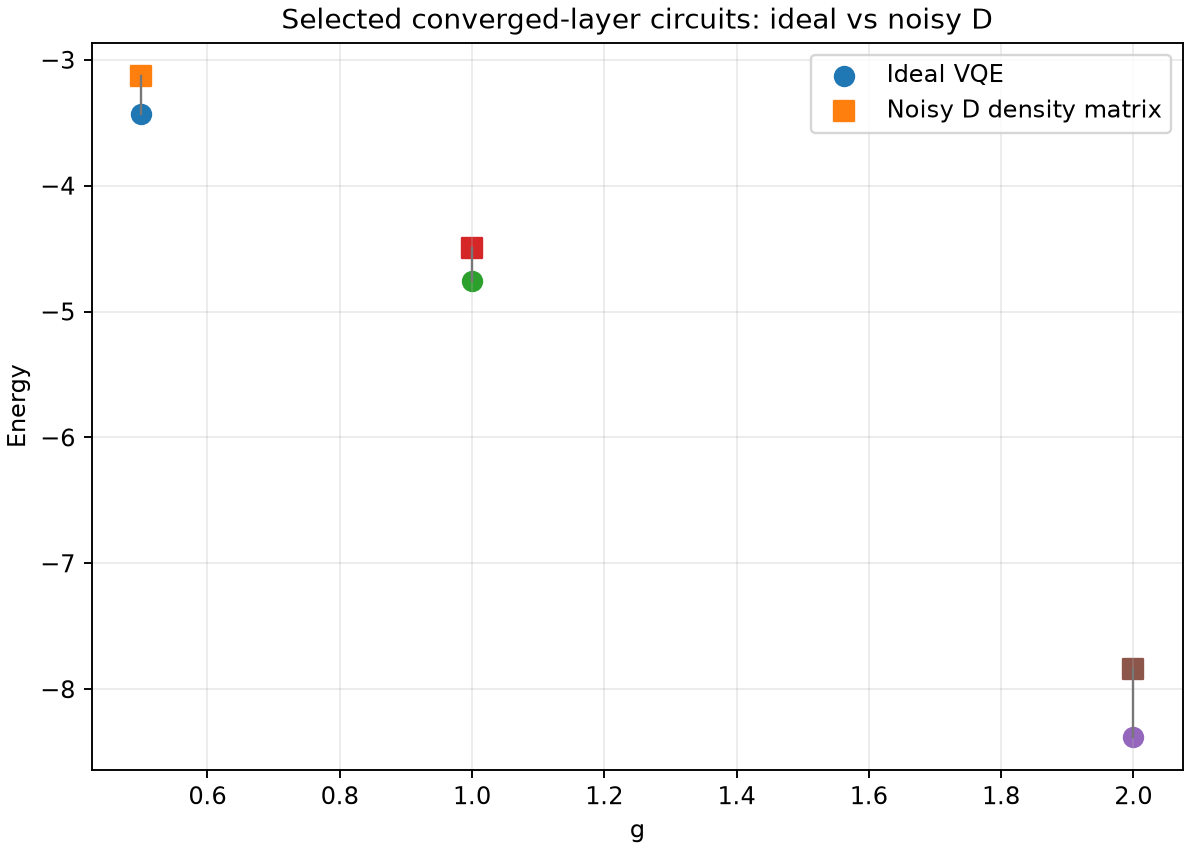

criticality_gap_entropy.png


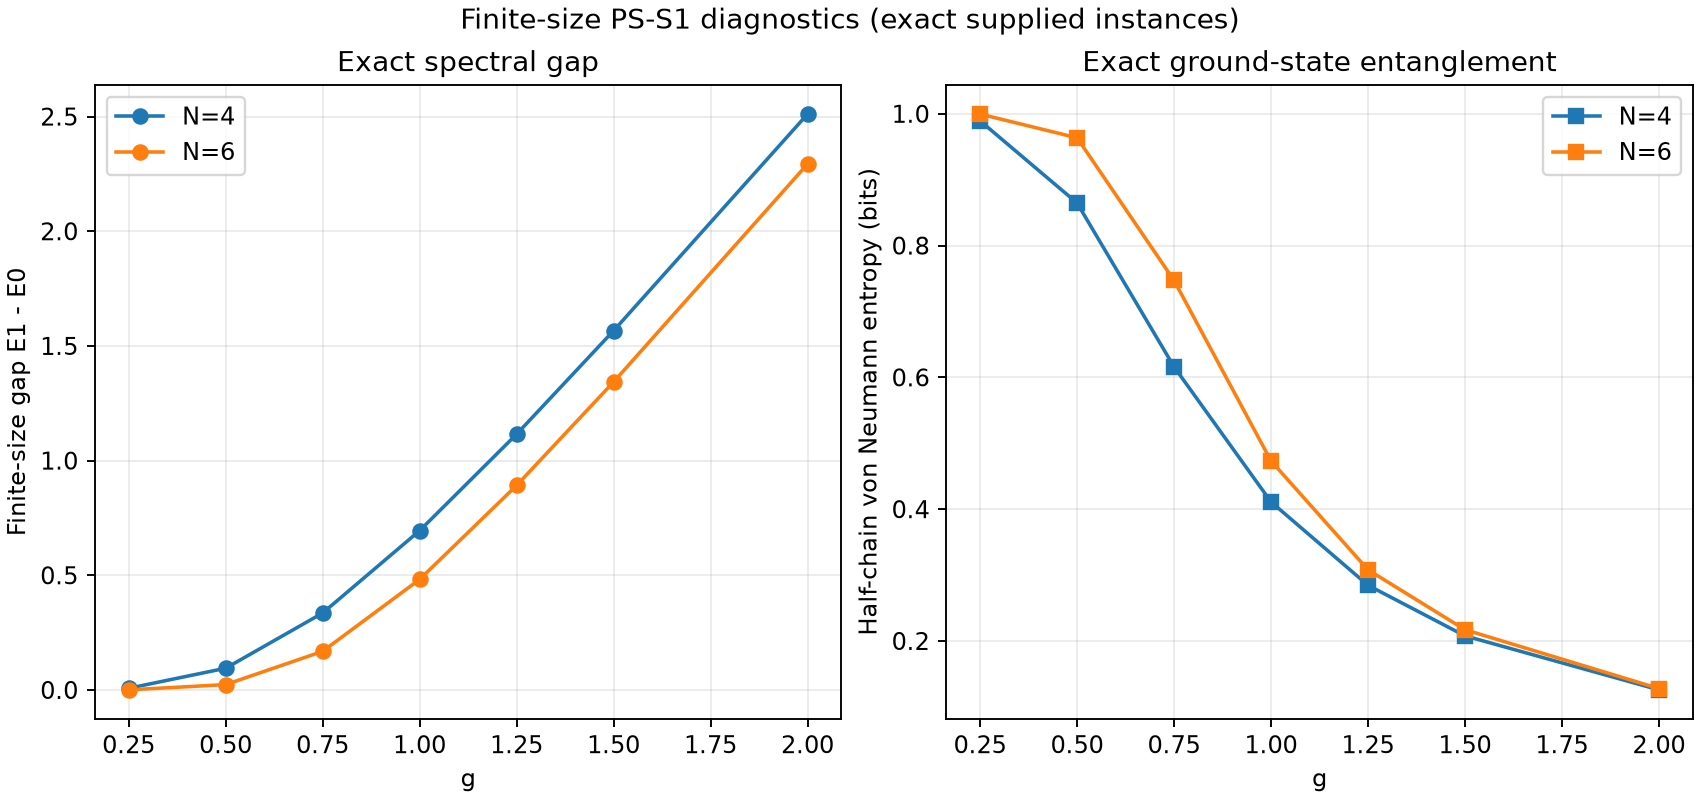

p2_sensitivity.png


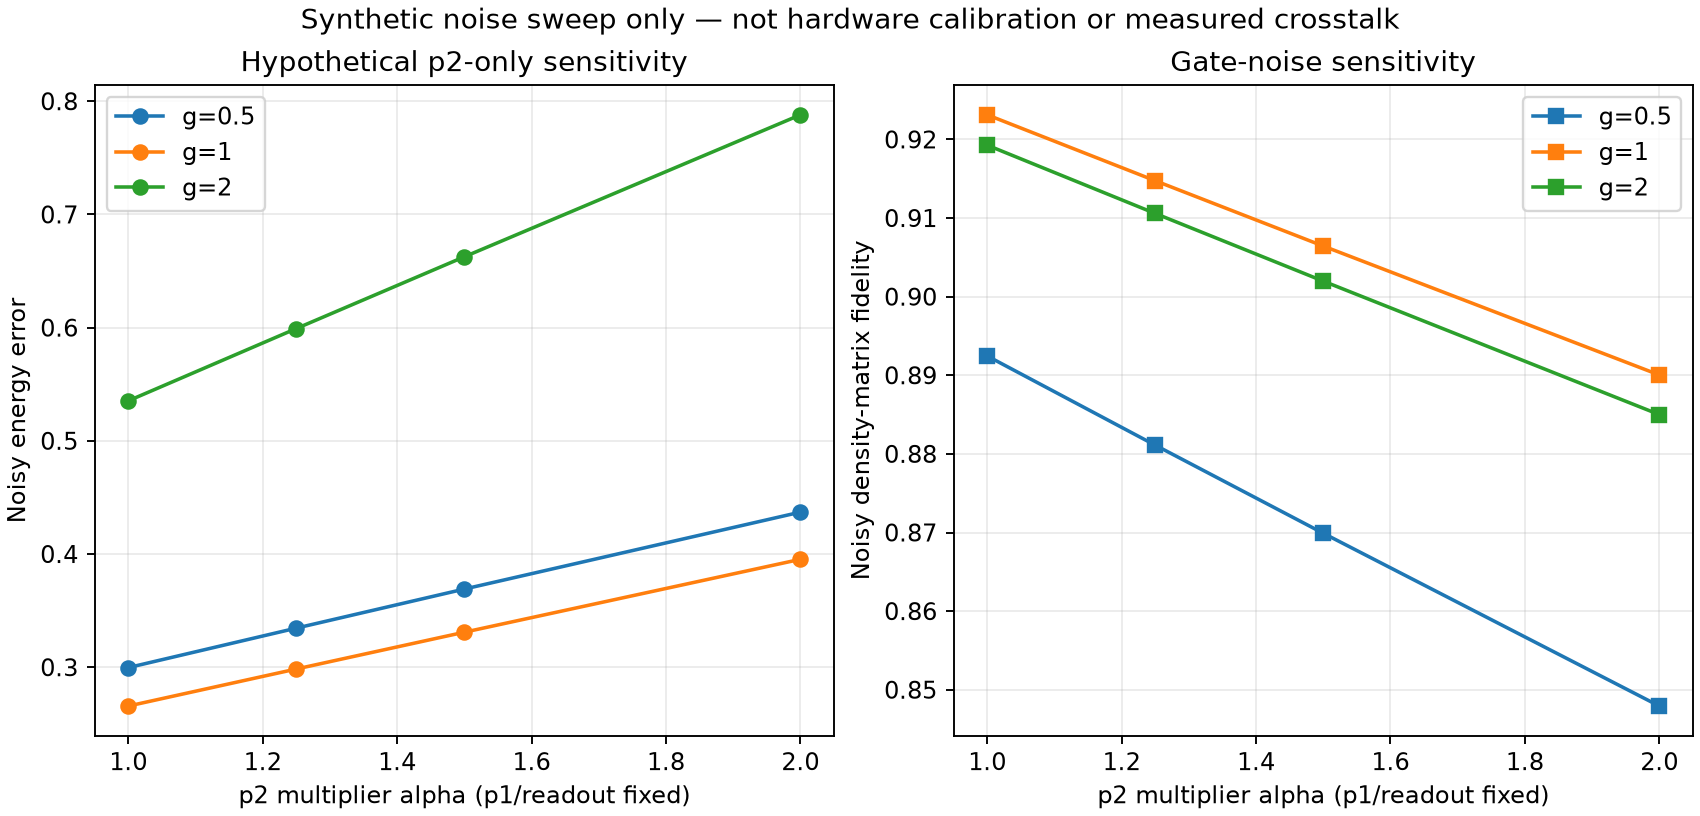

p2_processor_comparison.png


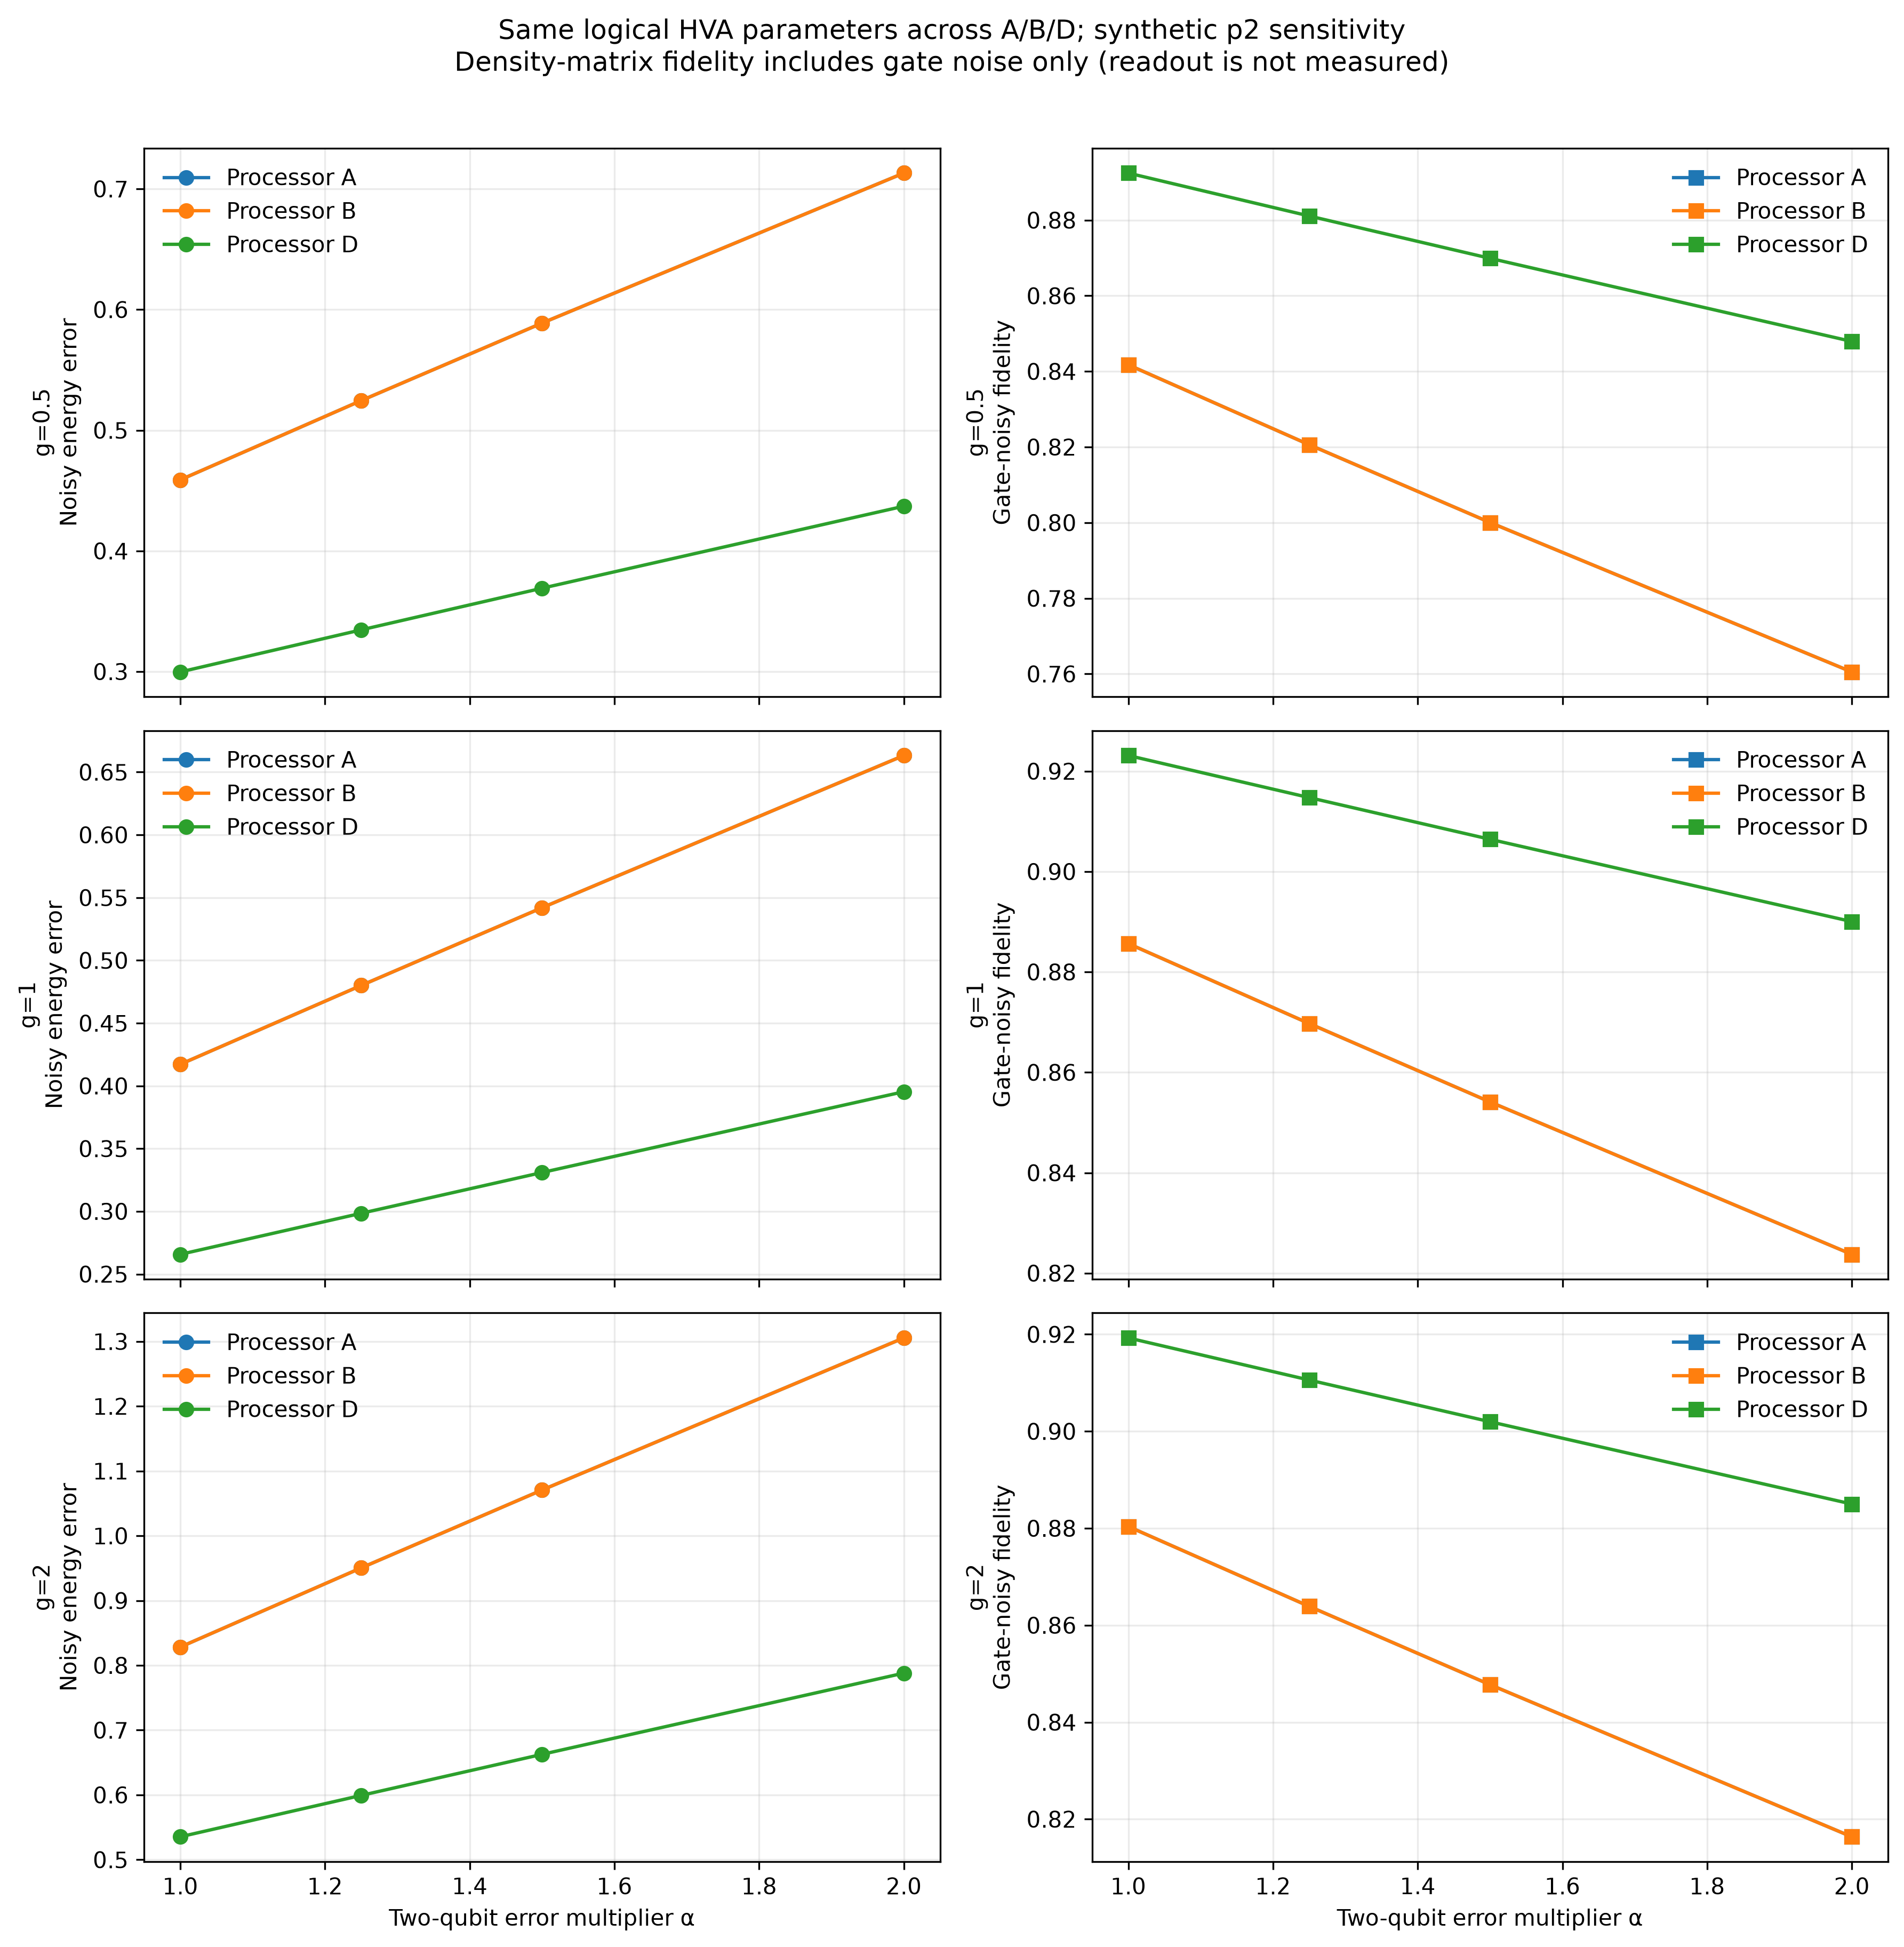

additional_n6_layer_study.png


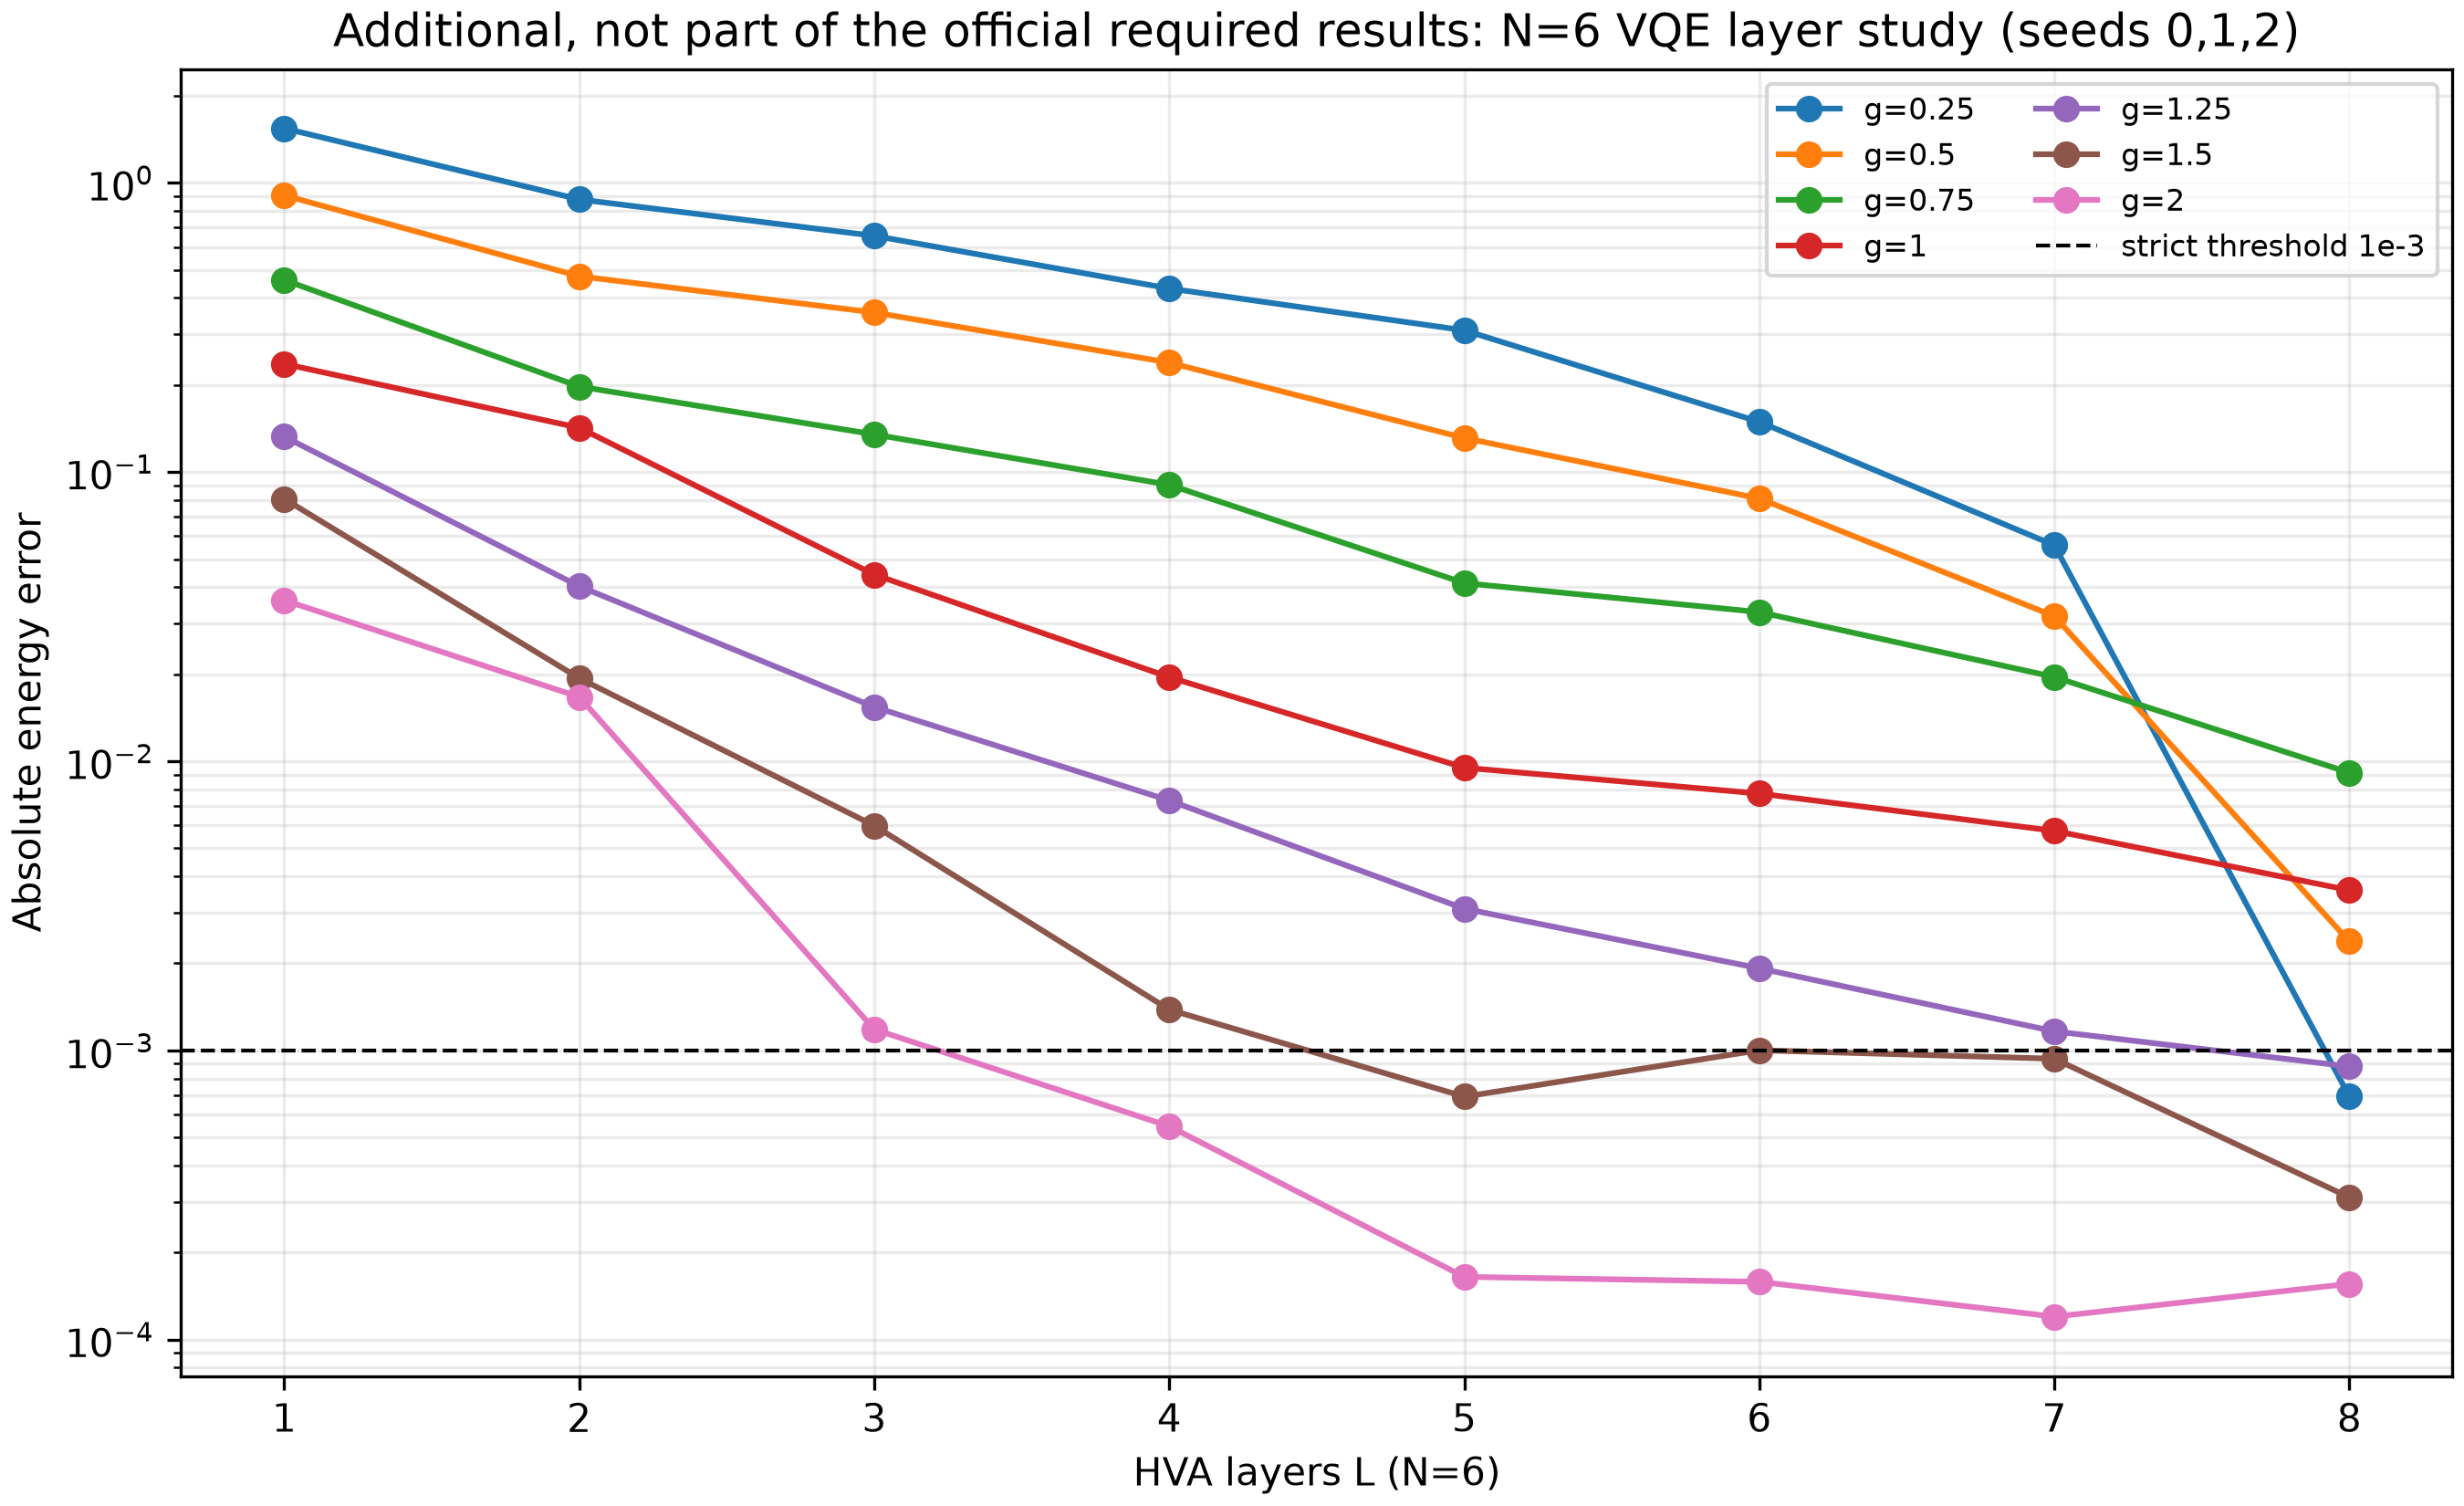

additional_finite_size_scaling.png


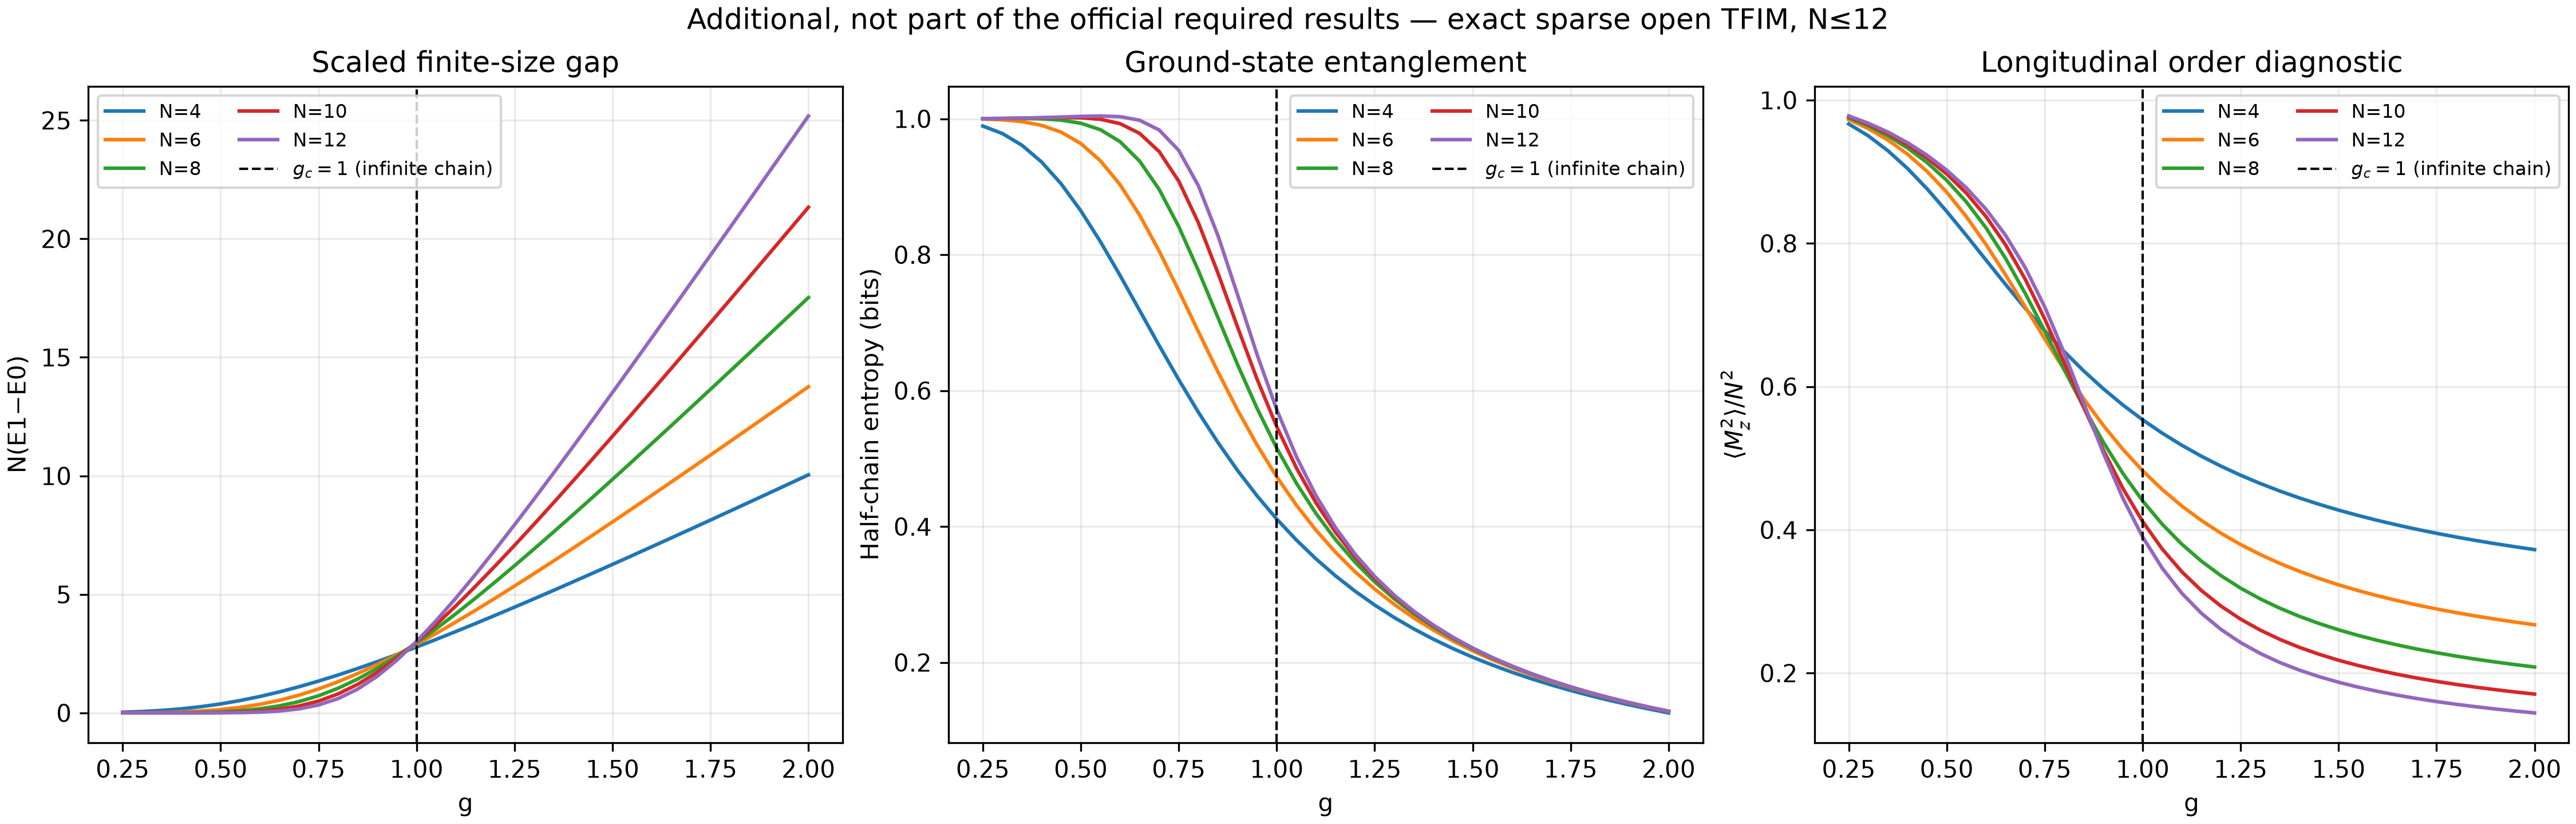

additional_mitigation_d.png


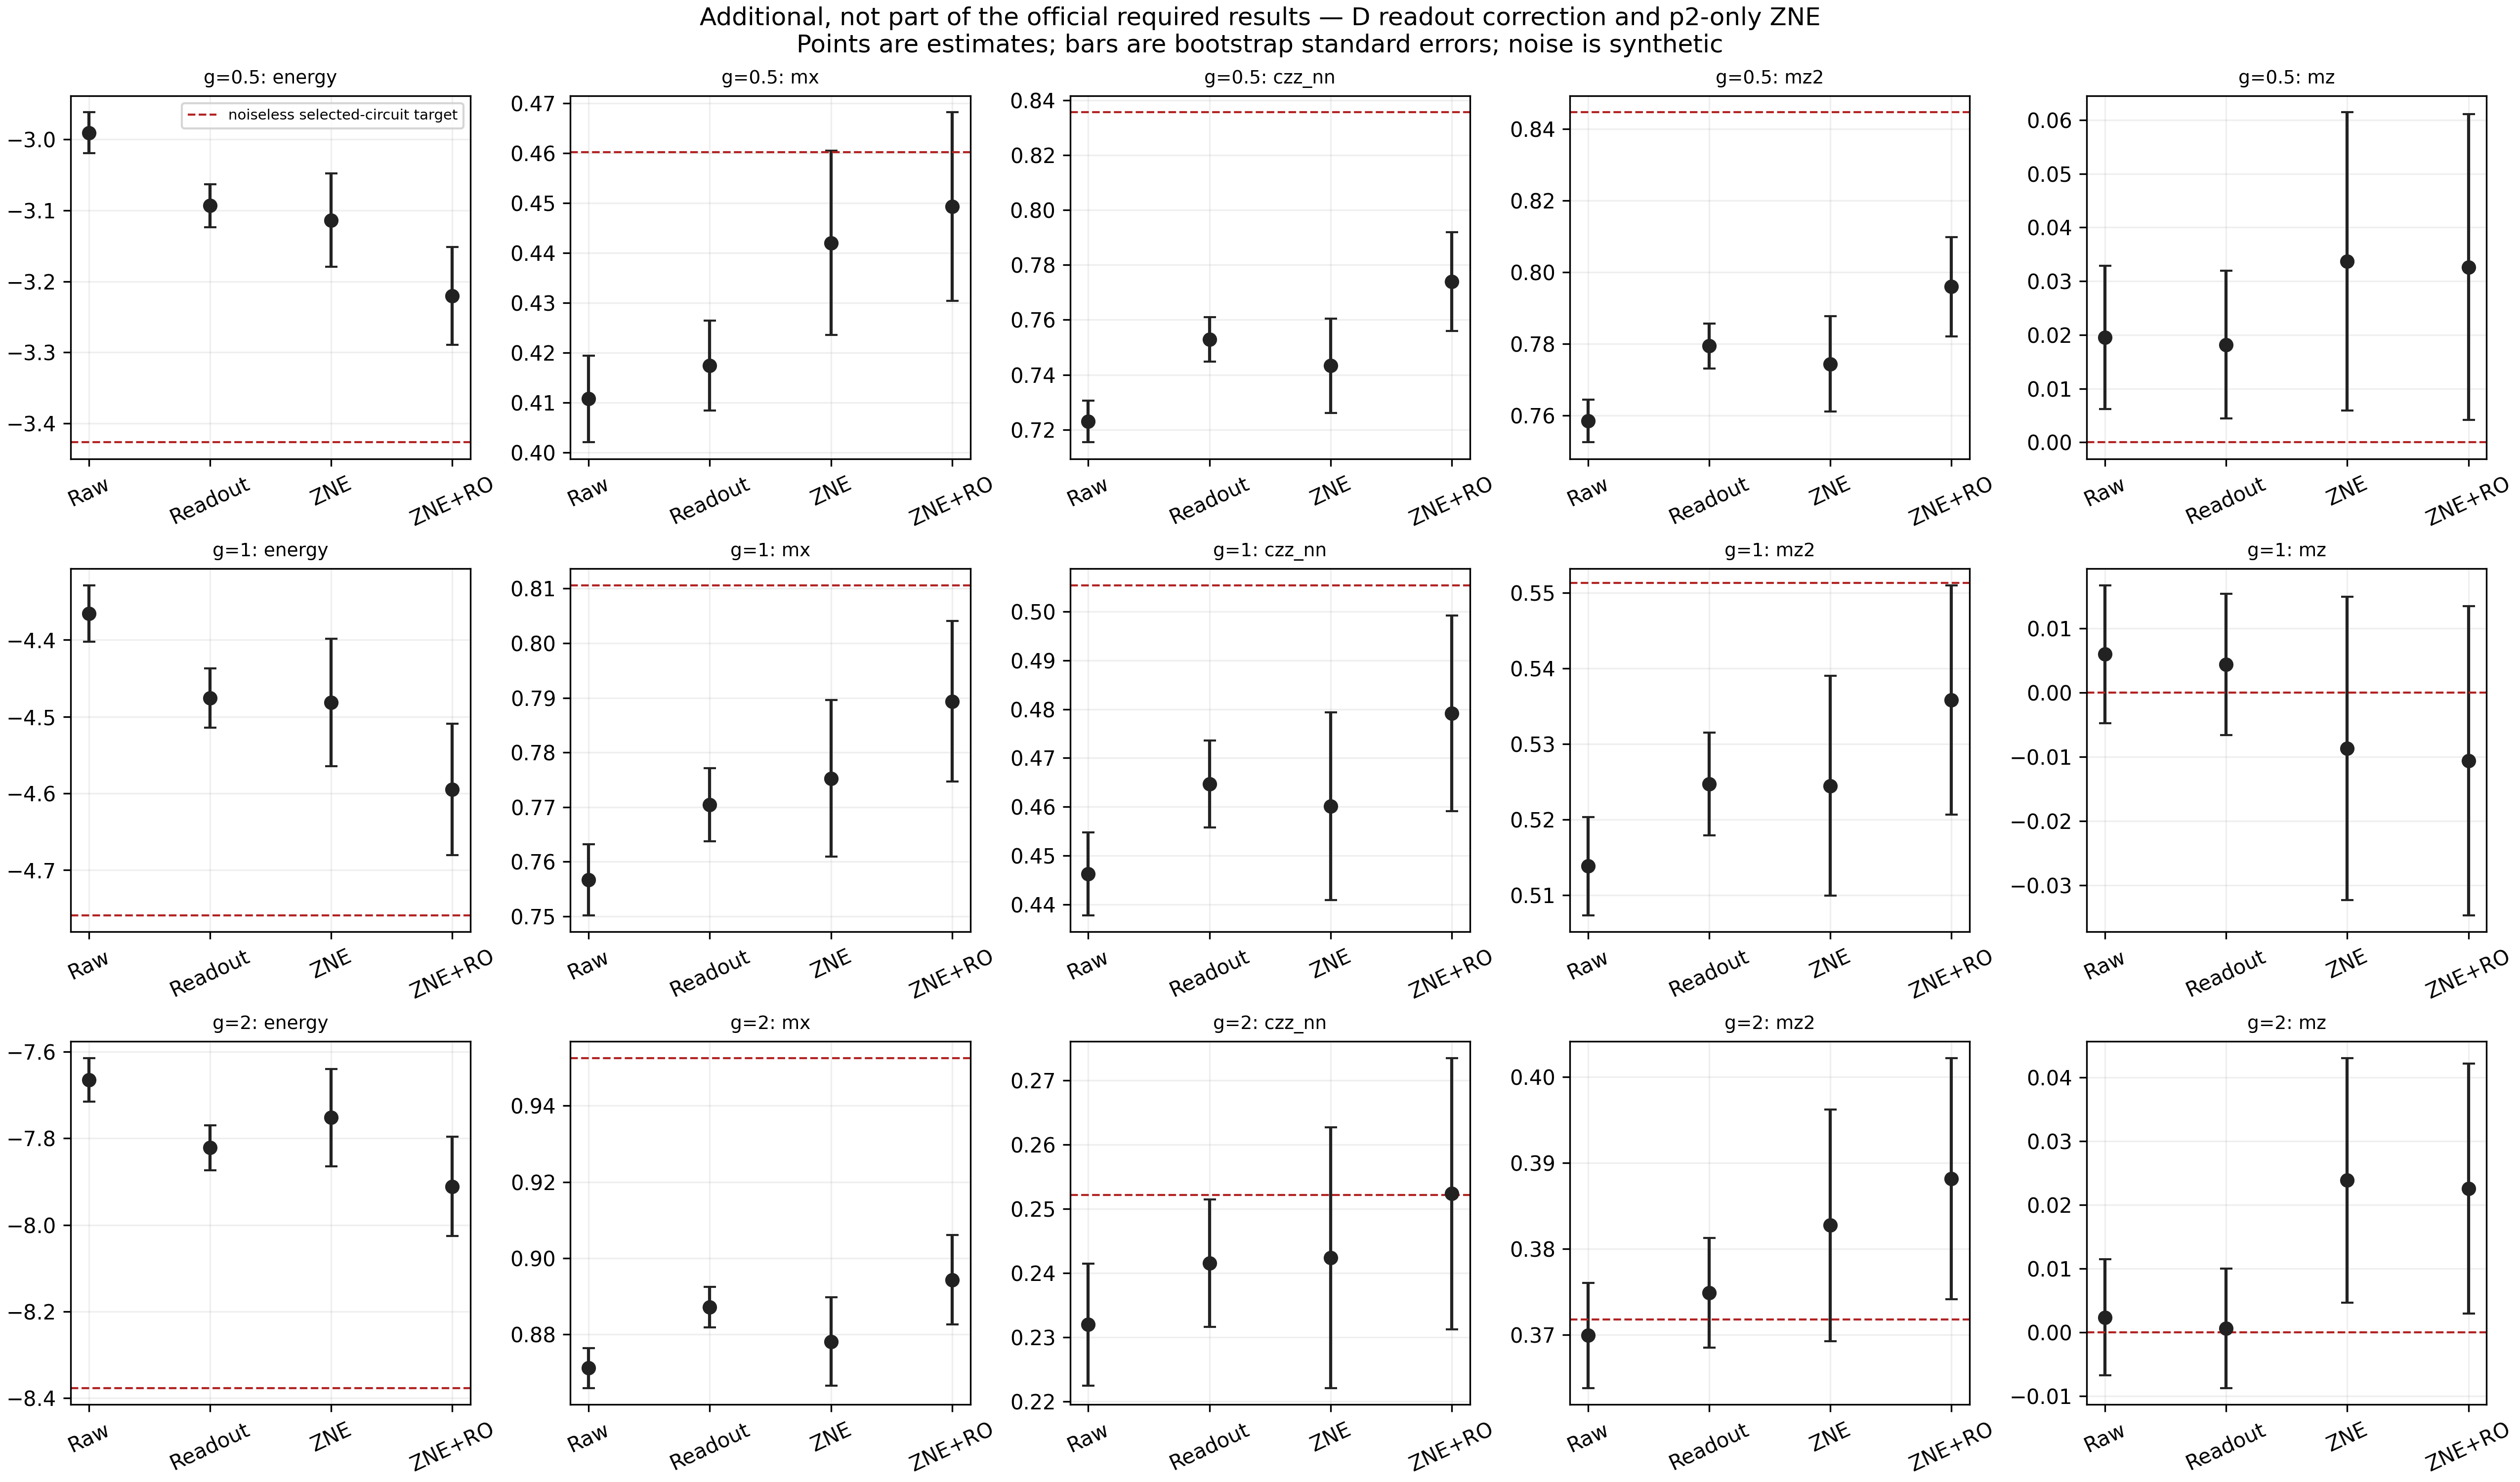

Additional-data CSVs: 14 criticality rows; 12 D-only p2-sensitivity rows; 36 A/B/D p2-comparison rows; 7 N=6 layer-summary rows; 180 finite-size rows; 15 D mitigation rows.


In [4]:
# Show the required plots and the explicitly separate research extensions.
from IPython.display import display, Image
for f in ['phase_observables_vs_g.png','layer_study_convergence.png','bell_comparison.png','processor_D_topology.png','noisy_vs_ideal_energy.png','criticality_gap_entropy.png','p2_sensitivity.png','p2_processor_comparison.png','additional_n6_layer_study.png','additional_finite_size_scaling.png','additional_mitigation_d.png']:
    p=ROOT/'results/figures'/f
    assert p.is_file(), f'Missing figure: {p}'
    print(f)
    display(Image(filename=str(p)))
print('Additional-data CSVs:', len(read_csv('results/additional/criticality.csv')), 'criticality rows;', len(read_csv('results/additional/p2_sensitivity.csv')), 'D-only p2-sensitivity rows;', len(p2_comparison), 'A/B/D p2-comparison rows;', len(n6_minimal), 'N=6 layer-summary rows;',len(finite_scaling),'finite-size rows;',len(mitigation),'D mitigation rows.')

## Interpretation and scope

At N=4 the HVA reproduces the exact ground state to numerical precision at L=4 across all seven g values; the minimum tested depth meeting the strict `|energy error| < 1e-3` condition is L=3 at g=1.0, 1.5 and 2.0, and L=4 at g=0.25, 0.5, 0.75 and 1.25. The finite-size transition is smooth. The staggered order diagnostic `mz` is zero (up to roundoff) for these symmetry-preserving states and is not the quantity that reveals the crossover; `mx`, `Czz_nn`, and `mz2` carry the visible trend. The density-matrix noisy runs and synthetic p2-only sensitivity are reported separately; the latter is not hardware calibration. The additional N=6 VQE tier now searches L=1..8 on seeds 0,1,2; numeric threshold results and optimizer success flags appear separately in the supplemental summary because several starts hit iteration limits and three g values remain above threshold. Processor D is a synthetic topology/noise proposal and not a claim about a calibrated device. Exact sparse finite-size scaling for N=4,6,8,10,12 is an additional, non-official comparison; N-gap crossings approach the known infinite-chain g_c=1 but do not establish the thermodynamic limit. See `results/additional/finite_size_scaling_interpretation.md`. See `report.md`, `docs/NUMBER_AUDIT.md`, and `docs/STATUS.md` for qualifications and evidence paths.

The D mitigation study is additional and uses synthetic sampling at g=0.5, 1.0, and 2.0. It compares raw estimates, local single-qubit readout-corrected estimates, linear p2-only zero-noise extrapolation at scales 1, 1.5, and 2, and the combined correction. Bootstrap standard errors appear beside the raw and mitigated estimates in `results/additional/mitigation_d_results.csv`; `mitigation_d_costs.csv` records the additional circuits and shots. Calibration and gate noise are synthetic. The reference is the noiseless expectation of the same saved HVA parameters, not an exact ground state. Extrapolation can increase uncertainty and does not imply hardware performance.
